# P2.3 · MLP regression on California housing (MSE vs Huber, RMSE and R² by hand)

**ID:** P2.3 · **Target:** 25 min · **Plan week:** 1 (timed repeat in week 3) · **Part:** P (PyTorch first principles)

**The drill.** Predict median house value (in units of \$100k) for 20 640 California block groups from 8 numeric
features. Use the P0 skeleton, standardize **X and y with train statistics only**, train the same MLP with
`MSELoss` and with `HuberLoss`, and report RMSE and R² **in original units**, computed by hand and checked
against scikit-learn.

**Must include (from the plan):** standardization without leakage, MSE vs Huber, RMSE and R². Also: trivial
baselines (predict the train mean; linear regression), initial-loss check (≈ 1 for standardized targets),
overfit-one-batch, `(N,)` vs `(N, 1)` shape discipline, eval over the whole set under `eval()` + `no_grad()`.

**Rules.** No docs, no LLM. The data is cached: `fetch_california_housing(data_home=DATA/"sklearn",
download_if_missing=False)`. Each solution cell keeps only its spec. The self-check names the variables it expects.

## Sources
- R. K. Pace, R. Barry, *Sparse spatial autoregressions*, Statistics & Probability Letters 33(3):291-297, 1997,
  DOI 10.1016/S0167-7152(96)00140-X — https://doi.org/10.1016/S0167-7152(96)00140-X (origin of the dataset).
- scikit-learn *California Housing dataset* description (features, target in \$100k, block groups):
  https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset
- scikit-learn `r2_score` / `root_mean_squared_error` (references for the by-hand checks):
  https://scikit-learn.org/stable/modules/model_evaluation.html#r2-score
- P. J. Huber, *Robust Estimation of a Location Parameter*, Ann. Math. Statist. 35(1):73-101, 1964,
  DOI 10.1214/aoms/1177703732 — https://doi.org/10.1214/aoms/1177703732
- `torch.nn.HuberLoss` docs (δ, relation to `SmoothL1Loss`): https://docs.pytorch.org/docs/stable/generated/torch.nn.HuberLoss.html
- `torch.nn.MSELoss` docs (broadcasting warning on mismatched shapes):
  https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html
- scikit-learn user guide, *Common pitfalls: data leakage during pre-processing*:
  https://scikit-learn.org/stable/common_pitfalls.html#data-leakage

In [1]:
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from prep import DATA, Session, check, check_close, seed_everything

s = Session("P2.3", target_min=25)
seed_everything(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

[P2.3] started 16:41; target 25 min


In [2]:
# 1. DATA. fetch_california_housing(data_home=DATA/"sklearn", download_if_missing=False) -> X (20640, 8), y (20640,).
#    Inspect feature names, ranges, the target's max (it is CAPPED: how many rows sit at the cap?).
#    Split 70/15/15 with train_test_split(test_size=0.30, random_state=0) then (test_size=0.50, random_state=0)
#    -> numpy X_train_np, X_val_np, X_test_np, y_train_np, y_val_np, y_test_np.
#    Standardize X with train mean/std -> `x_mu`, `x_sd` and y with train mean/std -> `y_mu`, `y_sd` (floats).
#    Tensors: X_train, X_val, X_test (float32, (N, 8)); y_train, y_val, y_test standardized float32 of shape (N,).
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

data = fetch_california_housing(data_home=DATA / "sklearn", download_if_missing=False)
X, y = data.data, data.target
print(X.shape, y.shape, data.feature_names)
print("feature min", X.min(0).round(2), "\nfeature max", X.max(0).round(2))
print(f"target range [{y.min():.3f}, {y.max():.3f}], rows at the cap: {(y >= 5.0).sum()}")
X_train_np, X_tmp, y_train_np, y_tmp = train_test_split(X, y, test_size=0.30, random_state=0)
X_val_np, X_test_np, y_val_np, y_test_np = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=0)
x_mu, x_sd = X_train_np.mean(0), X_train_np.std(0)
y_mu, y_sd = float(y_train_np.mean()), float(y_train_np.std())
fx = lambda a: torch.tensor((a - x_mu) / x_sd, dtype=torch.float32)
fy = lambda a: torch.tensor((a - y_mu) / y_sd, dtype=torch.float32)
X_train, X_val, X_test = fx(X_train_np), fx(X_val_np), fx(X_test_np)
y_train, y_val, y_test = fy(y_train_np), fy(y_val_np), fy(y_test_np)
print(X_train.shape, y_train.shape, f"y_mu={y_mu:.3f} y_sd={y_sd:.3f}")

(20640, 8) (20640,) ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
feature min [   0.5     1.      0.85    0.33    3.      0.69   32.54 -124.35] 
feature max [ 1.50000e+01  5.20000e+01  1.41910e+02  3.40700e+01  3.56820e+04
  1.24333e+03  4.19500e+01 -1.14310e+02]
target range [0.150, 5.000], rows at the cap: 992
torch.Size([14448, 8]) torch.Size([14448]) y_mu=2.068 y_sd=1.154


In [3]:
# 2. METRICS BY HAND (numpy or torch, ORIGINAL units).
#    rmse(y, yhat) = sqrt(mean((y - yhat)^2)).
#    r2(y, yhat) = 1 - SS_res / SS_tot, SS_tot = sum((y - mean(y))^2) using the mean of the TRUE y.
#    Baselines on val (original units): predict the train mean (`base_mean` dict with "rmse", "r2"),
#    and sklearn LinearRegression on the standardized X (`base_lin` dict).
from sklearn.linear_model import LinearRegression


def rmse(y, yhat):
    y, yhat = np.asarray(y, dtype=np.float64), np.asarray(yhat, dtype=np.float64)
    assert y.shape == yhat.shape, (y.shape, yhat.shape)
    return float(np.sqrt(np.mean((y - yhat) ** 2)))


def r2(y, yhat):
    y, yhat = np.asarray(y, dtype=np.float64), np.asarray(yhat, dtype=np.float64)
    assert y.shape == yhat.shape, (y.shape, yhat.shape)
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))


base_mean = {"rmse": rmse(y_val_np, np.full_like(y_val_np, y_train_np.mean())),
             "r2": r2(y_val_np, np.full_like(y_val_np, y_train_np.mean()))}
lin = LinearRegression().fit(X_train.numpy(), y_train_np)
base_lin = {"rmse": rmse(y_val_np, lin.predict(X_val.numpy())), "r2": r2(y_val_np, lin.predict(X_val.numpy()))}
print("val baselines  mean:", base_mean, " linear:", base_lin)

val baselines  mean: {'rmse': 1.153459753823427, 'r2': -0.0007067261562172522}  linear: {'rmse': 0.7333562126578267, 'r2': 0.5954875636460926}


**The `(N, 1)` vs `(N,)` trap.** Run this before you write the model: the "loss" below is not the MSE of the
predictions, even though it returns a number.

In [4]:
pred_col = (0.8 * y_val + 0.1)[:, None]  # (N, 1): a decent predictor whose Linear(…, 1) output you forgot to squeeze
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    bad = nn.functional.mse_loss(pred_col, y_val)  # broadcasts to (N, N)!
print(f"broadcast 'MSE' {bad:.4f} vs correct {nn.functional.mse_loss(pred_col.squeeze(1), y_val):.4f};",
      "warning:", w[0].category.__name__ if w else None)
print("hand-written version broadcasts silently:", ((pred_col - y_val) ** 2).shape)

broadcast 'MSE' 1.6474 vs correct 0.0489; warning: UserWarning
hand-written version broadcasts silently: torch.Size([3096, 3096])


In [5]:
# 3. MODEL. `MLP`: 8 -> 128 -> 128 -> 1, ReLU, forward returns shape (B,) (squeeze the last dim).
#    `make_model()` -> fresh model on `dev`. DataLoaders: train batch 256 shuffle; val/test batch 4096.
#    `predict(model, X) -> ORIGINAL-unit numpy predictions` (model.eval(), no_grad, then * y_sd + y_mu).
class MLP(nn.Module):
    def __init__(self, d_in=8, d_h=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_h), nn.ReLU(), nn.Linear(d_h, d_h), nn.ReLU(), nn.Linear(d_h, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def make_model():
    return MLP().to(dev)


train_dl = DataLoader(TensorDataset(X_train, y_train), batch_size=256, shuffle=True)
val_dl = DataLoader(TensorDataset(X_val, y_val), batch_size=4096)


@torch.no_grad()
def predict(model, X):
    model.eval()
    out = torch.cat([model(xb.to(dev)).cpu() for xb in X.split(4096)])
    return out.double().numpy() * y_sd + y_mu

In [6]:
# 4. SANITY CHECKS. (a) `init_mse`: MSE of a fresh model on standardized val targets (≈ Var(y_std) ≈ 1).
#    (b) Overfit one batch of 64 with a fresh model, Adam lr=1e-3, 500 steps, MSE -> `overfit_loss` (< 0.01).
torch.manual_seed(0)
m0 = make_model()
with torch.no_grad():
    init_mse = nn.functional.mse_loss(m0(X_val.to(dev)), y_val.to(dev)).item()
print(f"init MSE {init_mse:.3f} (Var of standardized val y = {y_val.var().item():.3f})")
tmp = make_model()
tmp_opt = torch.optim.Adam(tmp.parameters(), lr=1e-3)
xb, yb = X_train[:64].to(dev), y_train[:64].to(dev)
for _ in range(500):
    loss = nn.functional.mse_loss(tmp(xb), yb)
    tmp_opt.zero_grad()
    loss.backward()
    tmp_opt.step()
overfit_loss = loss.item()
print(f"overfit-one-batch MSE {overfit_loss:.5f}")

init MSE 0.987 (Var of standardized val y = 0.999)


overfit-one-batch MSE 0.00000


In [7]:
# 5. TRAIN FUNCTION. `fit(loss_fn, epochs=40, lr=1e-3) -> (model, history)` on a FRESH seeded model
#    (torch.manual_seed(0) inside, so MSE and Huber start from the same init): AdamW (wd=1e-4),
#    CosineAnnealingLR over the epochs, per epoch: train with `loss_fn` on standardized y; record train loss and
#    val RMSE in ORIGINAL units (via predict) in history["train_loss"], history["val_rmse"].
#    Keep the best-val-RMSE state_dict and load it before returning.
def fit(loss_fn, epochs=40, lr=1e-3):
    torch.manual_seed(0)
    model = make_model()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    history = {"train_loss": [], "val_rmse": []}
    best, best_state = float("inf"), None
    for _ in range(epochs):
        model.train()
        tot, n = 0.0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(dev), yb.to(dev)
            out = model(xb)
            assert out.shape == yb.shape
            loss = loss_fn(out, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(yb)
            n += len(yb)
        sched.step()
        v = rmse(y_val_np, predict(model, X_val))
        history["train_loss"].append(tot / n)
        history["val_rmse"].append(v)
        if v < best:
            best, best_state = v, {k: t.detach().clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, history

mse   val RMSE 0.5471  MAE 0.3732  R2 0.7748


huber val RMSE 0.5450  MAE 0.3686  R2 0.7766


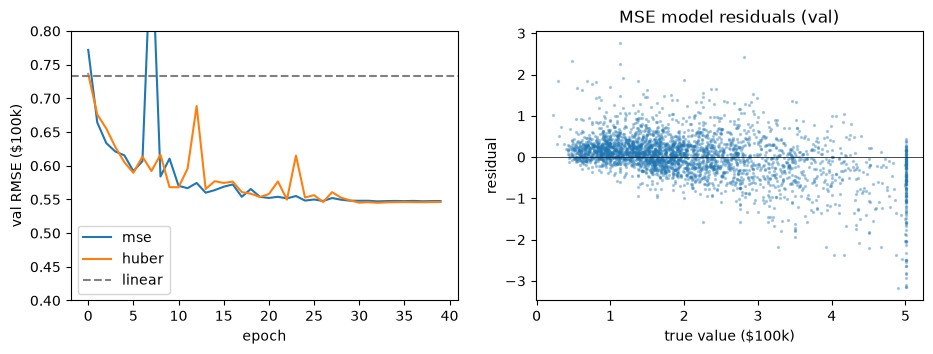

In [8]:
# 6. MSE vs HUBER. results = {"mse": ..., "huber": ...}, each a dict with "model", "history",
#    "val_rmse", "val_mae", "val_r2" (ORIGINAL units, by hand; MAE = mean |y - yhat|).
#    Huber: nn.HuberLoss(delta=1.0) on standardized targets (delta is in units of y_sd: say what that means).
#    Plot val RMSE curves of both, and residuals (yhat - y) vs y on val for the MSE model: look at the cap.
results = {}
for name, lf in [("mse", nn.MSELoss()), ("huber", nn.HuberLoss(delta=1.0))]:
    m, h = fit(lf)
    p = predict(m, X_val)
    results[name] = {"model": m, "history": h, "val_rmse": rmse(y_val_np, p),
                     "val_mae": float(np.mean(np.abs(y_val_np - p))), "val_r2": r2(y_val_np, p)}
    print(f"{name:5s} val RMSE {results[name]['val_rmse']:.4f}  MAE {results[name]['val_mae']:.4f}  R2 {results[name]['val_r2']:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for name in results:
    ax[0].plot(results[name]["history"]["val_rmse"], label=name)
ax[0].axhline(base_lin["rmse"], ls="--", c="gray", label="linear")
ax[0].set(xlabel="epoch", ylabel="val RMSE ($100k)", ylim=(0.4, 0.8)); ax[0].legend()
p = predict(results["mse"]["model"], X_val)
ax[1].scatter(y_val_np, p - y_val_np, s=2, alpha=0.3)
ax[1].axhline(0, c="k", lw=0.5)
ax[1].set(xlabel="true value ($100k)", ylabel="residual", title="MSE model residuals (val)")
plt.show()

In [9]:
# 7. TEST (once). Pick the loss with the lower val RMSE -> `best_name`. On test, ORIGINAL units:
#    `test_rmse`, `test_r2`, `test_mae`. Print RMSE also in dollars.
best_name = min(results, key=lambda k: results[k]["val_rmse"])
p_test = predict(results[best_name]["model"], X_test)
test_rmse, test_r2 = rmse(y_test_np, p_test), r2(y_test_np, p_test)
test_mae = float(np.mean(np.abs(y_test_np - p_test)))
print(f"chosen: {best_name}; test RMSE {test_rmse:.4f} (= ${test_rmse * 1e5:,.0f}), MAE {test_mae:.4f}, R2 {test_r2:.4f}")

chosen: huber; test RMSE 0.5251 (= $52,505), MAE 0.3545, R2 0.7935


## Self-check
Expects: `x_mu`, `x_sd`, `y_mu`, `y_sd`, `X_train`, `y_train`, `rmse`, `r2`, `base_mean`, `init_mse`, `overfit_loss`,
`results` (keys "mse", "huber" each with "model", "val_rmse", "val_r2"), `predict`, `test_rmse`, `test_r2`.

In [10]:
from sklearn.metrics import mean_squared_error, r2_score

_X, _y = fetch_california_housing(data_home=DATA / "sklearn", download_if_missing=False, return_X_y=True)
_Xtr, _, _ytr, _ = train_test_split(_X, _y, test_size=0.30, random_state=0)
check_close("x_mu from TRAIN split only", np.asarray(x_mu, dtype=np.float64), _Xtr.mean(0), rtol=1e-6)
check_close("x_sd from TRAIN split only", np.asarray(x_sd, dtype=np.float64), _Xtr.std(0), rtol=1e-3)
check_close("y_mu / y_sd from TRAIN split only", [y_mu, y_sd], [_ytr.mean(), _ytr.std()], rtol=1e-3)
check("targets are (N,) float", y_train.ndim == 1 and y_train.dtype == torch.float32, f"got {tuple(y_train.shape)} {y_train.dtype}")
rng = np.random.default_rng(0)
a, b = rng.normal(2, 1, 300), rng.normal(2, 1.5, 300)
check_close("rmse == sklearn", rmse(a, b), math.sqrt(mean_squared_error(a, b)))
check_close("r2 == sklearn", r2(a, b), r2_score(a, b))
check_close("r2(y, y) == 1", r2(a, a), 1.0)
check_close("r2 of the mean predictor == 0", r2(a, np.full_like(a, a.mean())), 0.0, atol=1e-9)
check("train-mean baseline R2 ~ 0 on val", abs(base_mean["r2"]) < 0.01, f"got {base_mean['r2']:.4f}")
check("model output is (B,)", results["mse"]["model"](X_val[:5].to(dev)).shape == (5,))
check("initial MSE ~ 1 (standardized y)", 0.5 < init_mse < 2.0, f"got {init_mse:.3f}")
check("can overfit one batch", overfit_loss < 0.01, f"got {overfit_loss:.5f}")
for k in ("mse", "huber"):
    pk = predict(results[k]["model"], X_val)
    check(f"{k}: predict() returns original units", abs(pk.mean() - y_val_np.mean()) < 0.3, f"mean pred {pk.mean():.3f}")
    check_close(f"{k}: stored val R2 matches sklearn", results[k]["val_r2"], r2_score(y_val_np, pk), atol=1e-6)
    check(f"{k}: beats linear regression", results[k]["val_rmse"] < base_lin["rmse"] - 0.05,
          f"{results[k]['val_rmse']:.3f} vs linear {base_lin['rmse']:.3f}")
check("test R2 > 0.75", test_r2 > 0.75, f"got {test_r2:.3f}")
check("test RMSE < 0.60 ($100k)", test_rmse < 0.60, f"got {test_rmse:.3f}")

ok  x_mu from TRAIN split only
ok  x_sd from TRAIN split only
ok  y_mu / y_sd from TRAIN split only
ok  targets are (N,) float
ok  rmse == sklearn
ok  r2 == sklearn
ok  r2(y, y) == 1
ok  r2 of the mean predictor == 0
ok  train-mean baseline R2 ~ 0 on val
ok  model output is (B,)
ok  initial MSE ~ 1 (standardized y)
ok  can overfit one batch
ok  mse: predict() returns original units
ok  mse: stored val R2 matches sklearn
ok  mse: beats linear regression
ok  huber: predict() returns original units
ok  huber: stored val R2 matches sklearn
ok  huber: beats linear regression
ok  test R2 > 0.75
ok  test RMSE < 0.60 ($100k)


## Say it out loud (P3)
1. Why standardize y as well as X? What goes wrong if you don't (think: init, LR, loss scale)?
2. Which likelihood does MSE maximize? Which does L1? Where does Huber sit, and what does δ = 1 mean here?
3. Why did the initial MSE come out ≈ 1? What would it be if you had *not* standardized y?
4. RMSE vs MAE vs R²: what does each tell a stakeholder? Can R² be negative?
5. The target is capped at 5.00001 (\$500k). How does that show up in the residual plot, and how would you handle it?
6. Where exactly can leakage enter this pipeline (list three places)?
7. `(N, 1)` vs `(N,)`: which PyTorch calls broadcast, which raise, which only warn?

<details><summary>Model answers</summary>

1. With raw y (mean ≈ 2.07, values up to 5) the network must first learn a large output bias. The loss scale
   also changes the effective LR and the meaning of Huber's δ. With standardized y the output starts near the
   target mean, the initial loss is ≈ 1, and the default LRs work. You must un-standardize (×σ_y + μ_y) before
   you report metrics.
2. MSE is the Gaussian negative log-likelihood with fixed variance (it predicts the conditional mean). L1 is the
   Laplace NLL (it predicts the conditional median). Huber is quadratic for |r| ≤ δ and linear beyond (Huber 1964),
   so it is robust to outliers while staying smooth at 0. On standardized targets δ = 1 means "residuals beyond
   one train standard deviation (σ_y ≈ \$115k) are penalized linearly".
3. A fresh MLP outputs ≈ constant c ≈ 0, so the MSE is E[(y − c)²] = Var(y) + (E[y] − c)² ≈ 1 for standardized
   y. Unstandardized, it would be ≈ Var(y) + E[y]² ≈ 1.33 + 4.3 ≈ 5.6.
4. RMSE is in the target's units (\$) and is dominated by large errors. MAE is the typical absolute error and is
   robust. R² = 1 − SS_res/SS_tot is the fraction of variance explained relative to predicting the mean. On held-out
   data R² is negative whenever the model is worse than the constant predictor. It is not bounded below.
5. 965 rows sit exactly at 5.00001 (992 at ≥ 5.0, about 4.8 %). In the residual plot they form a vertical stripe
   at x = 5 with mostly negative residuals: their true value is "\$500k or more", and the model predicts lower.
   The cap is censoring, not noise. Options: drop the capped rows (and say so), use a censored (Tobit-style)
   likelihood, or report metrics on capped and uncapped rows separately. Huber penalizes their large residuals
   only linearly, so they pull the fit less than under MSE.
6. (i) Fitting the scaler (or any imputer/PCA/feature selection) on all data before splitting. (ii) Tuning
   hyperparameters or picking checkpoints on the test set. (iii) Spatial/near-duplicate leakage: neighbouring block
   groups share prices, so a random split is optimistic compared with a split by geography.
7. `F.mse_loss`, `l1_loss` and `huber_loss` broadcast (N,1) against (N,) to (N,N) with only a `UserWarning`.
   A hand-written `(pred - y) ** 2` broadcasts silently. `BCEWithLogitsLoss` raises a `ValueError`. Guard with
   `squeeze(-1)` in `forward` and `assert out.shape == y.shape`.
</details>

In [11]:
s.finish(lookups=0, score=None, notes="")  # score: 1-5 self-rating; notes: what tripped you up

[P2.3] done in 0.3 min (within target 25 min)


0.28479665915171304